# Local Contribution of SLH Episodes: Median Profile Difference

Besides the aggregate metrics (mean, SD, TIR, TAR…), the **local contribution of SLH episodes to the daily glucose profile** is quantified. For each participant, the median observed and the median counterfactual glucose profiles are computed at each time of day over the 45-day analysis window, together with their difference Δm(t). The notebook reports **t_max**, the time of day at which |Δm(t)| is maximal, and the corresponding maximum absolute difference **|Δm(t_max)|** (in mmol/L).

Equivalent computation in the pipeline: `compute_max_median_diff` in `scripts/counterfactual/sensitivity_analysis.py` (`python3 -m scripts.counterfactual.sensitivity_analysis --patient_id ALL`).

**Usage** — from the repository root, point the notebook at a data folder and open it
(the 4-patient synthetic sample is enough: `make sample_data_run`):

```bash
CGM_DATA_ROOT=$PWD/sample_data jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the **synthetic sample dataset** (`make sample_data`: fake patients A001–A004, simulated glucose, time expressed relative to an arbitrary t = 0). It contains **no real patient data**, and the numbers and figures are not expected to match the manuscript.

## Definitions

For a participant, let $G$ be the observed glucose signal and $C$ the counterfactual signal in which every SLH episode is
replaced (zone expansion $\delta$, linear interpolation between local minima, rolling-mean smoothing; see `04_counterfactual.ipynb`).
For each time-of-day slot $t$ (resolution = the CGM sampling interval, 5 min), pooling the 45 days of the window:

$$m_G(t) = \operatorname{median}_{d}\, G_d(t), \qquad m_C(t) = \operatorname{median}_{d}\, C_d(t)$$

$$\Delta m(t) = m_C(t) - m_G(t)$$

$$t_{\max} = \arg\max_t \, |\Delta m(t)|, \qquad |\Delta m(t_{\max})| = \max_t \, |\Delta m(t)|$$

A negative $\Delta m(t)$ means the counterfactual median is **lower** than the observed one at that time of day (removing the episodes
lowered glucose there). Glucose is reported in **mmol/L** (mg/dL ÷ 18.0182). Formal definitions are given in the
Supplementary methods (equations S5–S9).

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    PATIENT_ID_COL, TIME_COL, GLUCOSE_COL, COL_FILEPATH, WINDOW_SUMMARY_CSV,
    COL_EPISODE_START, COL_EPISODE_END, COL_EPISODE_DURATION, COL_EPISODE_CLASSIFICATION, CLASSIFICATION_SLH,
)
from src.config.paths import FILTER_STATUS_CSV
from src.preprocessing.load_data import load_window_data
from src.preprocessing.timestep import detect_dominant_sampling_interval
from src.episodes.load_episodes import prepare_episode_data, load_patient_episodes
from src.filtering.load_filtering import load_filtered_patient_list
from src.agp.compute_agp import compute_agp_profile
from src.counterfactual.counterfactual_config import SELECTED_OFFSET_MIN, KERNEL_MIN
from src.counterfactual.build_counterfactual import build_full_counterfactual_signal
from src.utils.unit_conversion import mgdl_to_mmoll

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

OFFSET_MIN = SELECTED_OFFSET_MIN     # δ (min)
C_OBS, C_CTF, C_DIFF = "0.35", "#D55E00", "#0072B2"
print(f"δ = {OFFSET_MIN} min, smoothing kernel = {KERNEL_MIN} min")

δ = 30 min, smoothing kernel = 60 min


## 2. Computing Δm(t), t_max and |Δm(t_max)|

`median_profile_difference` builds the counterfactual signal of one participant, computes the two median profiles and returns Δm(t) in mmol/L.

In [2]:
def median_profile_difference(df, slh_episodes, timestep_min, offset_min=OFFSET_MIN):
    """Observed and counterfactual median profiles (mmol/L) and Δm(t) = m_C(t) − m_G(t)."""
    counterfactual = build_full_counterfactual_signal(df, slh_episodes, offset_min, timestep_min)

    df_ctf = df.copy()
    df_ctf[GLUCOSE_COL] = counterfactual

    observed = compute_agp_profile(df, timestep_min)
    ctf = compute_agp_profile(df_ctf, timestep_min)

    profile = pd.DataFrame({
        "time": observed["time_str"],
        "m_G": mgdl_to_mmoll(observed["median"].to_numpy()),
        "m_C": mgdl_to_mmoll(ctf["median"].to_numpy()),
    })
    profile["delta_m"] = profile["m_C"] - profile["m_G"]
    return profile


def t_max_summary(profile):
    """t_max (time of day of the largest |Δm|), |Δm(t_max)| and its sign."""
    d = profile["delta_m"].abs()
    if d.notna().sum() == 0:
        return None
    i = int(np.nanargmax(d.to_numpy()))
    return {"t_max": profile["time"].iloc[i], "abs_delta_m_tmax": float(d.iloc[i]),
            "delta_m_tmax": float(profile["delta_m"].iloc[i])}


def load_participant(patient_id):
    """Window data, SLH episodes (as dicts) and sampling interval for one participant."""
    windows = pd.read_csv(WINDOW_SUMMARY_CSV).set_index(PATIENT_ID_COL)
    df = prepare_episode_data(load_window_data(windows.loc[patient_id, COL_FILEPATH]))
    episodes = load_patient_episodes(patient_id)
    slh = episodes[episodes[COL_EPISODE_CLASSIFICATION] == CLASSIFICATION_SLH]
    slh_episodes = [{"onset_time": r[COL_EPISODE_START], "offset_time": r[COL_EPISODE_END],
                     "duration_min": r[COL_EPISODE_DURATION]} for _, r in slh.iterrows()]
    return df, slh_episodes, detect_dominant_sampling_interval(df)

## 3. One participant

The participant with the most SLH episodes is shown.

In [3]:
windows = pd.read_csv(WINDOW_SUMMARY_CSV)
def count_slh(pid):
    """Number of SLH episodes of a participant (0 if there is no episode file: no episode detected)."""
    episodes = load_patient_episodes(pid)
    return 0 if episodes is None else int((episodes[COL_EPISODE_CLASSIFICATION] == CLASSIFICATION_SLH).sum())


n_slh = {pid: count_slh(pid) for pid in windows[PATIENT_ID_COL]}
patient_id = max(n_slh, key=n_slh.get)

df, slh_episodes, timestep_min = load_participant(patient_id)
profile = median_profile_difference(df, slh_episodes, timestep_min)
summary = t_max_summary(profile)

print(f"Participant {patient_id}: {len(slh_episodes)} SLH episodes")
print(f"t_max = {summary['t_max']}   |Δm(t_max)| = {summary['abs_delta_m_tmax']:.2f} mmol/L "
      f"(Δm = {summary['delta_m_tmax']:+.2f})")

Participant A003: 181 SLH episodes
t_max = 07:25   |Δm(t_max)| = 3.39 mmol/L (Δm = -3.39)


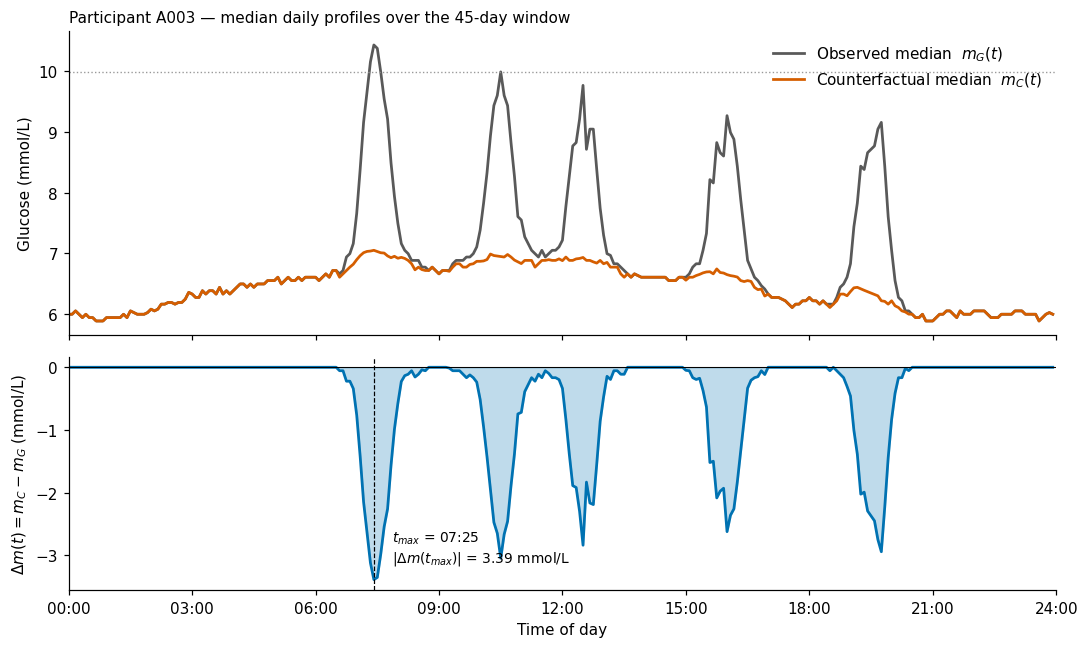

In [4]:
hours = np.arange(len(profile)) * timestep_min / 60
t_max_h = hours[profile["time"].tolist().index(summary["t_max"])]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})

ax1.plot(hours, profile["m_G"], color=C_OBS, lw=1.8, label="Observed median  $m_G(t)$")
ax1.plot(hours, profile["m_C"], color=C_CTF, lw=1.8, label="Counterfactual median  $m_C(t)$")
ax1.axhline(mgdl_to_mmoll(180), color="0.6", ls=":", lw=0.9)
ax1.set_ylabel("Glucose (mmol/L)")
ax1.legend(frameon=False)
ax1.set_title(f"Participant {patient_id} — median daily profiles over the 45-day window", loc="left", fontsize=10)

ax2.fill_between(hours, profile["delta_m"], 0, color=C_DIFF, alpha=0.25)
ax2.plot(hours, profile["delta_m"], color=C_DIFF, lw=1.8)
ax2.axhline(0, color="k", lw=0.7)
ax2.axvline(t_max_h, color="k", ls="--", lw=0.8)
ax2.annotate(f"$t_{{max}}$ = {summary['t_max']}\n$|\\Delta m(t_{{max}})|$ = {summary['abs_delta_m_tmax']:.2f} mmol/L",
             xy=(t_max_h, summary["delta_m_tmax"]), xytext=(12, 12), textcoords="offset points", fontsize=9)
ax2.set_ylabel("$\\Delta m(t) = m_C - m_G$ (mmol/L)")
ax2.set_xlabel("Time of day")
ax2.set_xlim(0, 24); ax2.set_xticks(range(0, 25, 3)); ax2.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 3)])
plt.tight_layout()
plt.show()

## 4. All participants

The same computation for every participant of the (filtered) cohort that has at least one SLH episode.

In [5]:
selected = load_filtered_patient_list(str(FILTER_STATUS_CSV))
participants = [pid for pid in windows[PATIENT_ID_COL] if n_slh[pid] > 0 and (selected is None or pid in selected)]

profiles, rows = {}, []
for pid in participants:
    df, slh_episodes, timestep_min = load_participant(pid)
    profiles[pid] = median_profile_difference(df, slh_episodes, timestep_min)
    rows.append({PATIENT_ID_COL: pid, "n_SLH": len(slh_episodes), **t_max_summary(profiles[pid])})

results = pd.DataFrame(rows).sort_values("abs_delta_m_tmax", ascending=False).reset_index(drop=True)
results.round(2)

  Filter CSV: 4 selected patients


,patient_id,n_SLH,t_max,abs_delta_m_tmax,delta_m_tmax
0,A003,181,07:25,3.39,-3.39
1,A001,149,16:00,2.83,-2.83
2,A002,57,07:40,1.61,-1.61
3,A004,10,07:30,0.26,-0.26


In [6]:
a = results["abs_delta_m_tmax"]
print(f"{len(results)} participants")
print(f"|Δm(t_max)|: median {a.median():.2f} mmol/L (IQR {a.quantile(.25):.2f}–{a.quantile(.75):.2f}), "
      f"range {a.min():.2f}–{a.max():.2f}")
print(f"Δm(t_max) < 0 (counterfactual lower) in {(results['delta_m_tmax'] < 0).mean():.0%} of participants")

4 participants
|Δm(t_max)|: median 2.22 mmol/L (IQR 1.27–2.97), range 0.26–3.39
Δm(t_max) < 0 (counterfactual lower) in 100% of participants


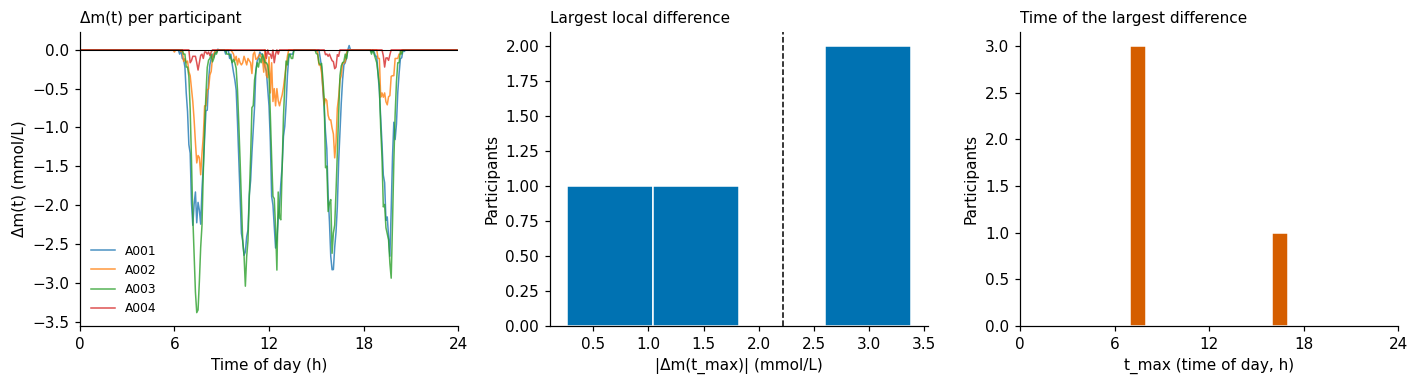

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# Δm(t) of every participant
hours = np.arange(len(next(iter(profiles.values())))) * 24 / len(next(iter(profiles.values())))
for pid, prof in profiles.items():
    axes[0].plot(hours, prof["delta_m"], lw=1, alpha=0.8, label=pid if len(profiles) <= 8 else None)
axes[0].axhline(0, color="k", lw=0.7)
axes[0].set_xlim(0, 24); axes[0].set_xticks(range(0, 25, 6))
axes[0].set_xlabel("Time of day (h)"); axes[0].set_ylabel("Δm(t) (mmol/L)")
axes[0].set_title("Δm(t) per participant", loc="left", fontsize=10)
if len(profiles) <= 8:
    axes[0].legend(frameon=False, fontsize=8)

# |Δm(t_max)|
axes[1].hist(results["abs_delta_m_tmax"], bins=min(15, max(len(results), 3)), color=C_DIFF, edgecolor="white")
axes[1].axvline(a.median(), color="k", ls="--", lw=1)
axes[1].set_xlabel("|Δm(t_max)| (mmol/L)"); axes[1].set_ylabel("Participants")
axes[1].set_title("Largest local difference", loc="left", fontsize=10)

# t_max
t_hours = pd.to_timedelta(results["t_max"] + ":00").dt.total_seconds() / 3600
axes[2].hist(t_hours, bins=np.arange(0, 25, 1), color=C_CTF, edgecolor="white")
axes[2].set_xlim(0, 24); axes[2].set_xticks(range(0, 25, 6))
axes[2].set_xlabel("t_max (time of day, h)"); axes[2].set_ylabel("Participants")
axes[2].set_title("Time of the largest difference", loc="left", fontsize=10)

plt.tight_layout()
plt.show()

## Notes

- Δm(t) is computed from **medians**, so it is robust to a few extreme days; it shows when in the day the SLH episodes weigh most on the typical profile.
- t_max and |Δm(t_max)| depend on the zone-expansion offset δ (here the selected value); `05_sensitivity_analysis.ipynb` and
  `compute_max_median_diff` report them for δ = 0–90 min.
- The sign convention here is Δm = counterfactual − observed; the reported magnitude |Δm(t_max)| does not depend on it.